# Dynamic programming

Jorge Arturo Montiel Navarro | A01278612

### Coin change
He have n different values, on an array C of coins. Example: 
    For n=4
    - C = [1,2,5,10]


You have to determine how many possible ways are to arrange a value K with those coins

### Tabulation method

First, instantiate a matrix n*m with internal values of 0, where:
    - n = C.size()+1
    - m = k+1

The value of the matrix on [0,0] has to be 1

Note: Creating a matrix on python has the following form
matrix = [[0]*cols for _ in range(rows)]

Cycle for in python follos the following pattern:
   - for i in range(x, limit)  -> starts on x and ends on **limit-1**
   - for i in range(x, limit, step) -> same but takes the size of the step specified

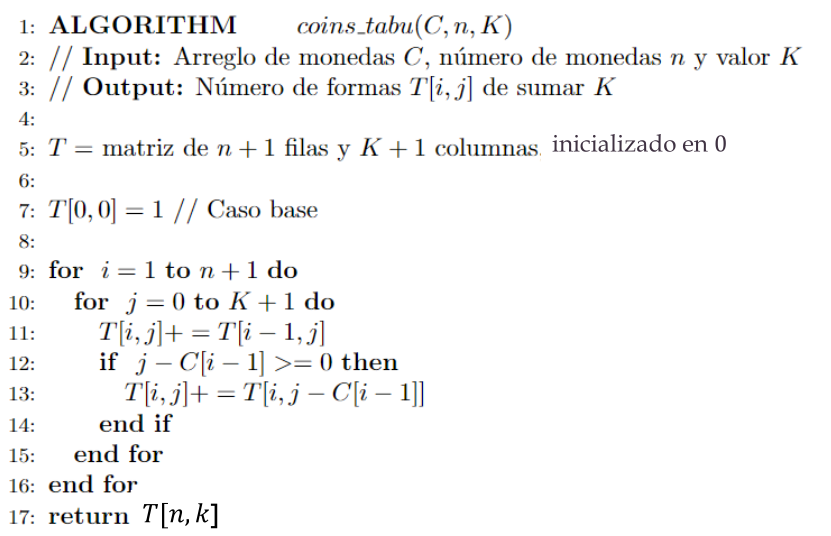

In [94]:
def coinChange_tabu(coins,k):
    T = [[0]*(k+1) for _ in range(len(coins)+1)]
    T[0][0]=1

    for i in range(1,len(coins)+1):
        for j in range(0,k+1):
            T[i][j]+=T[i-1][j]
            if j-coins[i-1] >= 0:
                T[i][j]+=T[i][j-coins[i-1]]

    return T[len(coins)][k]

**Time complexity:** O(n*k) where n is the number of coins, and k is the expected sum. 
- Why? You have a nested loop traversing n times arrays of k elements
**Space complexity:** O(n*k) to store the table for tabulation method

In [ ]:
C = [1,2,5,10]
print(coinChange_tabu(C,5))
print(coinChange_tabu(C,10))
print(coinChange_tabu(C,10))


4
11


### Memoization method
Initially the first difference relies on the creation of the matrix with internal values of -1 and memo is previously constructed

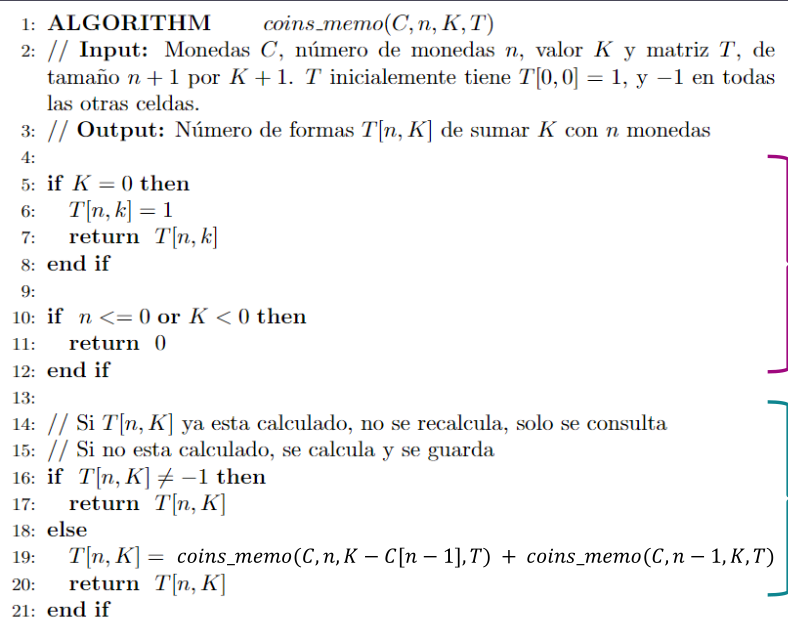


In [96]:
def coinChange_memo(coins,n,k,memo):

    if k == 0: # Reachable. as it is for this coin, you can return 1 to sum on the top of that
        memo[len(coins)][k] = 1
        return memo[len(coins)][k]

    if n <=0 or k < 0:  # Borders of the memo, not reachable
        return 0

    if memo[n][k] != -1: ## Already computed, return computed value
        return memo[n][k]

    memo[n][k]=coinChange_memo(coins,n,k-coins[n-1],memo) + coinChange_memo(coins,n-1,k,memo)
    return memo[n][k]



**Time complexity:** O(n*k) where n is the number of coins, and k is the expected sum. 
- Why? You compute the value of each square of the grid once, and then accesed for recursively across function calls using memoization
**Space complexity:** O(n*k) to store the memoization grid/matrix

In [97]:
k1=5
k2=10

memo1 = [[-1]*(k1+1) for _ in range(len(C)+1)]
memo1 [0][0]=1
print(coinChange_memo(C,len(C),k1,memo1))

memo2 = [[-1]*(k2+1) for _ in range(len(C)+1)]
memo2 [0][0]=1
print(coinChange_memo(C,len(C),k2,memo2))

4
11


## Coin collecting
On a n*n grid, some squares  cointain a golden coin
Determine how many coins can a robot collect 
Constraints:
- The robot starts on the left superior cell of the grid and only can move down or right
- The traverse of the grid ends on the bottom right cell of the grid

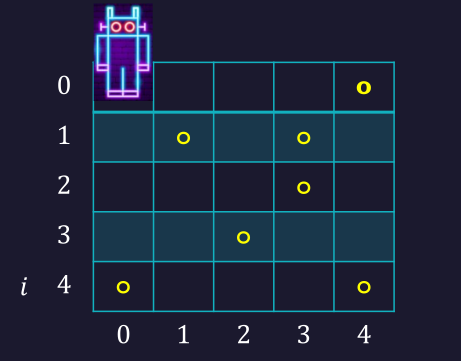
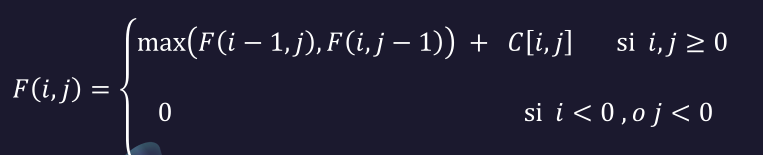

In [98]:
def coinCollecting_tabu(grid):
    T = [[0]*len(grid[0]) for _ in range(len(grid))]
    for i in range (len(grid)):
        for j in range (len(grid[0])):
            T[i][j]=grid[i][j]
            up = 0
            left = 0
            if i-1 >=0:
                up =T[i-1][j]
            if j-1 >=0:
                left=T[i][j-1]
            T[i][j]+=max(up,left)

    return T[len(grid)-1][len(grid[0])-1]

**Time complexity:** O(n*n) where n is the lenght of the square. 
- Why? As you have a nested loop of n over n to compute the result of each cell to compute the last one (the result).
**Space complexity:** O(n*n) to store the tabulation matrix which is the same size as the original grid

In [99]:
def coinCollecting_memo(grid,memo, i,j):
    if (i<0 or j<0):
        return 0

    if memo[i][j]!=-1:
        return memo[i][j]

    memo[i][j]=grid[i][j] + max(coinCollecting_memo(grid,memo,i-1,j),coinCollecting_memo(grid,memo,i,j-1)) 
    return memo[i][j]

**Time complexity:** O(n*n) where n is the lenght of the square. 
- Why? You compute the value of a memoization grid of size n*n backwards, the optimization using a memoization technique results on a complexity of n*n instead of n⁴
**Space complexity:** O(n*n) to store the tabulation matrix which is the same size as the original grid

In [ ]:
files= [ 
    "coins_input/coins-n5.txt",
    "coins_input/coins-n7.txt",
    "coins_input/coins-n8.txt",
    "coins_input/coins-n9.txt",
    "coins_input/coins-n10.txt",
    "coins_input/coins-n12.txt",
    "coins_input/coins-n100.txt"
]

for i in range(len(files)): ## IA used for understanding the I/O of files in python
    filename=files[i]
    with open(filename, "r") as file:
        # 1. Read the dimension of the grid
        n = int(file.readline().strip())
        
        # 2. Create the grid
        grid = [list(map(int, file.readline().split())) for _ in range(n)]



        print(filename)
        print(coinCollecting_tabu(grid))
        memo = [[-1]*n for _ in range(n)]
        print(coinCollecting_memo(grid,memo,n-1,n-1))


coinCollecting/coins-n5.txt
23
23
coinCollecting/coins-n7.txt
29
29
coinCollecting/coins-n8.txt
37
37
coinCollecting/coins-n9.txt
38
38
coinCollecting/coins-n10.txt
49
49
coinCollecting/coins-n12.txt
57
57
coinCollecting/coins-n100.txt
624
624


### Explicación
Utilizar DP para solucionar este problema es posible ya que lo que ocupamos es el valor "anterior" para computar el siguiente, y así sucesivamente.
La naturaleza de ir hacia atrás para saber el que necesitamos actualmente permite utilizar una "memoria" en la que almacenamos estos valores analizados y posteriormente acceder a ellos en tiempo constante.

Pero, ¿Como estamos seguros de que esto es verdad? ¿Como sabemos que la respuesta anterior nos sirve para la actual?

Partimos de el siguiente enfoque, el valor máximo para la casilla (0,0) es el valor de esa misma casilla, siendo ese un caso base.
Ahora, que pasa en una cuadrícula del estilo:
  ```
0 1 1
1 0 1
1 0 1
  ```

Si queremos calcular el valor para (2,2), queremos saber el camino máximo que tomó antes, las únicas casillas que pudo haber tocado antes fueron (2,1) y (1,2).

Y antes que esas pudo haber pasado por   ``` (2,0), (1,1) o (1,1) (0,2)   ```

Y antes pudo haber tomado   ``` (1,0), (1,0), (0,1), (1,0), (0,1), (0,1)   ```

y antes que eso tuvo que haber pasado por (0,0)

Aqui se notan cosas intersantes:
- **Overlapping subproblems** Vemos que varias celdas se necesitan computar varias veces cuando haces el camino para atrás
- Que un estado actual solo tiene **2 posibles estados anteriores**

Y si guardamos los resultados que ya analizamos? -> Programación dinámica para ahorrrar espacio
Y si solo calculamos el máximo de los anteriores en vez de hacer mucho rollo ? -> Solución eficiente



